# 37 — Where the pipeline stops: low masses, binary neutron stars, NSBH and eccentric systems

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What it does.** Extensions 11, 12 and 13. The analysis unit of the project is one second of data in the band 30–500 Hz, which fits binary black holes of 30–100 M☉. Rather than rebuilding the pipeline for 4–8 s windows and 16 kHz data (a new project), this notebook *quantifies the limits*:

* **A. SNR retained** (extensions 11, 12). For equal-mass IMRPhenomD signals from 6 M☉ to 100 M☉ and for a 1.4 + 1.4 M☉ binary, the fraction of the optimal SNR² that falls (i) in the 30–500 Hz band and (ii) in the band *and* in the last one second before the merger (the content of a 1 s window placed on the merger), computed with the PSD of the test chunks; the longest signals need windows of the order of their duration.
* **B. NSBH and eccentric sources** (extension 13). Libraries of 500 IMRPhenomNSBH signals (BH 20–60 M☉, NS 1.2–2 M☉, tidal deformability 0–800, aligned BH spin) and 500 EccentricFD signals (inspiral only, 15–40 M☉ total, e₀ = 0, 0.2, 0.4 at 20 Hz) are injected into the test noise and detected by the IMR bank, the sine-Gaussian bank, the two CNNs (with and without IMR training) and excess power, against an IMRPhenomD library of the same masses.

**What it does not do.** No window longer than one second, no sampling above 2048 Hz, no matched filter for the low-mass or NS systems (the IMR bank has total masses 30–100 M☉ and no tidal or eccentric templates); eccentric waveforms stop at the end of the inspiral; the NSBH tidal disruption is only as good as IMRPhenomNSBH.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, pickle
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import lal, lalsimulation as ls
import seq_models as sm
import imr_tools as it
import gwosc_tools as g
g.style()
rng = np.random.default_rng(37)
CH = {i: g.load_chunk(i) for i in range(len(g.chunks()))}
ch3 = CH[3]; f_psd, S_psd = ch3["f_psd"], ch3["S"]

## A. SNR content of the 1 s, 30-500 Hz window

In [2]:
def retention(m1, m2, T=128.0, fmax=2048.0):
    hp, hc = ls.SimInspiralChooseFDWaveform(m1 * lal.MSUN_SI, m2 * lal.MSUN_SI, 0, 0, 0, 0, 0, 0, 1e6 * lal.PC_SI, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0 / T, 20.0, fmax, 20.0, None, ls.IMRPhenomD)
    H = np.array(hp.data.data); f = np.arange(len(H)) / T; Sf = np.interp(f, f_psd, S_psd); r2 = 4 * np.abs(H) ** 2 / Sf / T
    full = r2[(f >= 20) & (f <= fmax)].sum(); band = r2[(f >= 30) & (f <= 500)].sum()
    Xb = np.where((f >= 30) & (f <= 500), H / np.sqrt(Sf), 0); x = np.fft.irfft(Xb, n=2 * (len(f) - 1)); fs = 2 * (len(f) - 1) / T; e = x ** 2; pk = np.argmax(e)
    win = e[max(int(pk - 0.75 * fs), 0): int(pk + 0.25 * fs)].sum() / e.sum()
    dur = float((np.cumsum(e) / e.sum() > 0.01).argmax()); t90 = (np.searchsorted(np.cumsum(e) / e.sum(), 0.99) - np.searchsorted(np.cumsum(e) / e.sum(), 0.01)) / fs
    return dict(frac_in_band=band / full, frac_band_and_last_second=band / full * win, duration_band_s=t90)
rows = [dict(system=f"{mt/2:g}+{mt/2:g} M☉ (M_tot {mt})", **retention(mt / 2, mt / 2)) for mt in (6, 8, 10, 15, 20, 30, 50, 100)]
rows.append(dict(system="BNS 1.4+1.4 M☉", **retention(1.4, 1.4, T=512.0, fmax=4096.0)))
RET = pd.DataFrame(rows).set_index("system"); RET["snr_factor_retained"] = np.sqrt(RET.frac_band_and_last_second); RET.round(3)

,frac_in_band,frac_band_and_last_second,duration_band_s,snr_factor_retained
system,,,,
3+3 M☉ (M_tot 6),0.526,0.237,13.596,0.487
4+4 M☉ (M_tot 8),0.464,0.256,8.501,0.506
5+5 M☉ (M_tot 10),0.843,0.533,5.837,0.730
7.5+7.5 M☉ (M_tot 15),0.967,0.759,2.955,0.871
10+10 M☉ (M_tot 20),0.964,0.864,1.894,0.929
15+15 M☉ (M_tot 30),0.968,0.928,127.750,0.964
25+25 M☉ (M_tot 50),0.978,0.940,127.999,0.970
50+50 M☉ (M_tot 100),0.982,0.865,128.000,0.930
BNS 1.4+1.4 M☉,0.036,0.008,47.562,0.087


## B. NSBH and eccentric systems

In [3]:
FS_G, T_G, FMIN = it.FS_GEN, it.T_GEN, it.FMIN
def to_window(hp, hc, fp, fc, tc):
    n = int(FS_G * T_G); H = fp * np.array(hp.data.data) + fc * np.array(hc.data.data); H = np.r_[H, np.zeros(max(0, n // 2 + 1 - len(H)))][: n // 2 + 1]
    ht = np.fft.irfft(H, n=n); ipk = int(np.argmax(np.abs(ht))); ht = np.roll(ht, int(round(tc * FS_G)) - ipk); w = ht[:FS_G].copy()
    r = int(0.04 * FS_G); w[:r] *= 0.5 * (1 - np.cos(np.pi * np.arange(r) / r)); r = int(0.02 * FS_G); w[-r:] *= 0.5 * (1 + np.cos(np.pi * np.arange(r) / r)); return (np.fft.rfft(w) / FS_G)[: g.NB]
def build(kind, n, seed):
    r = np.random.default_rng(seed); th = np.arccos(r.uniform(-1, 1, n)); ph = r.uniform(0, 2 * np.pi, n); psi = r.uniform(0, np.pi, n); fp, fc = it.antenna(th, ph, psi); tc = r.uniform(0.55, 0.88, n); cosi = r.uniform(-1, 1, n); H = np.zeros((n, g.NB), np.complex64); mt = np.zeros(n); ok = np.ones(n, bool)
    for i in range(n):
        try:
            if kind == "NSBH":
                mb, mn = r.uniform(20, 60), r.uniform(1.2, 2.0); d = lal.CreateDict(); ls.SimInspiralWaveformParamsInsertTidalLambda2(d, float(r.uniform(0, 800))); ls.SimInspiralWaveformParamsInsertTidalLambda1(d, 0.0)
                hp, hc = ls.SimInspiralChooseFDWaveform(mb * lal.MSUN_SI, mn * lal.MSUN_SI, 0, 0, r.uniform(-0.5, 0.8), 0, 0, 0.0, 1e6 * lal.PC_SI, np.arccos(cosi[i]), 0.0, 0, 0, 0, 1 / T_G, FMIN, FS_G / 2, FMIN, d, ls.IMRPhenomNSBH); mt[i] = mb + mn
            elif kind.startswith("ecc"):
                e0 = float(kind[3:]); M_ = r.uniform(15, 40); q = r.uniform(0.5, 1); m1 = M_ / (1 + q); m2 = M_ - m1
                hp, hc = ls.SimInspiralChooseFDWaveform(m1 * lal.MSUN_SI, m2 * lal.MSUN_SI, 0, 0, 0, 0, 0, 0, 1e6 * lal.PC_SI, np.arccos(cosi[i]), 0.0, 0, e0, 0, 1 / T_G, FMIN, FS_G / 2, FMIN, None, ls.EccentricFD); mt[i] = M_
            else:                                                  # IMRPhenomD baseline with the masses of the eccentric/NSBH prior
                M_ = r.uniform(30, 60) if kind == "D_nsbh" else r.uniform(15, 40); q = r.uniform(0.5, 1); m1 = M_ / (1 + q); m2 = M_ - m1
                hp, hc = ls.SimInspiralChooseFDWaveform(m1 * lal.MSUN_SI, m2 * lal.MSUN_SI, 0, 0, 0, 0, 0, 0, 1e6 * lal.PC_SI, np.arccos(cosi[i]), 0.0, 0, 0, 0, 1 / T_G, FMIN, FS_G / 2, FMIN, None, ls.IMRPhenomD); mt[i] = M_
            H[i] = to_window(hp, hc, fp[i], fc[i], tc[i])
        except Exception: ok[i] = False
    H = H / np.max(np.abs(H)); return dict(H=H[ok], mtot=mt[ok])
LIBS = {}
for kind, lab in (("NSBH", "NSBH (BH 20-60 + NS)"), ("D_nsbh", "IMRPhenomD, 30-60 M☉ (control)"), ("ecc0.0", "EccentricFD e0=0"), ("ecc0.2", "EccentricFD e0=0.2"), ("ecc0.4", "EccentricFD e0=0.4"), ("D_ecc", "IMRPhenomD, 15-40 M☉ (control)")):
    fn = os.path.join(g.CACHE, f"lib37_{kind}.npz")
    if os.path.exists(fn): LIBS[lab] = dict(np.load(fn))
    else: LIBS[lab] = build(kind, 500, seed=hash(kind) % 1000); np.savez_compressed(fn, **LIBS[lab])
    print(lab, LIBS[lab]["H"].shape)

NSBH (BH 20-60 + NS) (500, 513)


IMRPhenomD, 30-60 M☉ (control) (500, 513)


EccentricFD e0=0 (500, 513)


EccentricFD e0=0.2 (500, 513)


EccentricFD e0=0.4 (500, 513)


IMRPhenomD, 15-40 M☉ (control) (500, 513)


In [4]:
V, ID = {}, {}
for sp in ("train", "val", "test"): V[sp], ID[sp], _ = g.load_split(sp)
S1te = np.stack([CH[i]["S1"] for i in ID["test"]])
NETS = {"CNN (no IMR in training)": [sm.train_variant("cnn_fresh", None, None, seed=s, verbose=False)[0] for s in (0, 1)], "CNN (trained with IMRPhenomD)": [sm.train_variant("cnn_fresh_imr", None, None, seed=s, verbose=False)[0] for s in (0, 1)]}
BK = {"sine-Gaussian bank": {c: g.SGBank(CH[c]["S1"]) for c in CH}, "IMR bank (30-100 M☉)": {c: it.IMRBank(CH[c]["S1"]) for c in CH}}
EP = g.ExcessPower().fit(V["train"])
def scores(ser, cid):
    o = {k: g.scan_mixed(ser, cid, b)["rho2"] for k, b in BK.items()}; o["excess power"] = EP.stat(ser)
    for k, nets in NETS.items(): o[k] = np.mean([m.predict(sm.clip(ser)[..., None], verbose=0, batch_size=1024)[:, 0] for m in nets], 0)
    return o
VAL = scores(V["val"], ID["val"]); THR = {far: {k: g.threshold_at_far(v, far) for k, v in VAL.items()} for far in (1e-2, 1e-3)}
SNR = [4, 5, 6, 7, 8, 10, 12, 16]; NINJ = 250; fn = os.path.join(g.CACHE, "stats37.pkl")
def inject(lib, norm, n):
    i = rng.choice(len(V["test"]), n, replace=False); k = rng.integers(0, len(lib["H"]), n); t0 = rng.uniform(-0.03, 0.03, n)
    W = lib["H"][k].astype(complex) * np.exp(-2j * np.pi * g.FREQ[None, :] * t0[:, None]); W = 2 * W / np.sqrt(S1te[i]) * g.BAND; W = W * (norm / np.sqrt(np.sum(np.abs(W) ** 2, axis=1)))[:, None]
    return g.to_series(g.to_bins(V["test"][i]) + W), ID["test"][i]
if os.path.exists(fn): RES = pickle.load(open(fn, "rb"))
else: RES = {(name, s): scores(*inject(lib, float(s), NINJ)) for name, lib in LIBS.items() for s in SNR}; pickle.dump(RES, open(fn, "wb"))
rows = []
for name in LIBS:
    for det in VAL:
        for far in (1e-2, 1e-3):
            e = [float((RES[(name, s)][det] > THR[far][det]).mean()) for s in SNR]; rows.append(dict(family=name, detector=det, FAP=far, rho50=g.snr_level(e, SNR, .5), eff_rho8=float(np.interp(8, SNR, e))))
R = pd.DataFrame(rows); R[R.FAP == 1e-2].pivot_table(index="detector", columns="family", values="rho50", sort=False).round(2)

family,NSBH (BH 20-60 + NS),"IMRPhenomD, 30-60 M☉ (control)",EccentricFD e0=0,EccentricFD e0=0.2,EccentricFD e0=0.4,"IMRPhenomD, 15-40 M☉ (control)"
detector,,,,,,
sine-Gaussian bank,8.99,8.08,8.73,8.57,8.51,8.93
IMR bank (30-100 M☉),10.76,5.29,6.98,7.38,7.39,6.53
excess power,11.01,9.03,9.88,9.97,9.66,10.84
CNN (no IMR in training),6.23,5.48,5.97,5.86,5.68,6.15
CNN (trained with IMRPhenomD),5.44,4.56,5.28,5.44,5.19,5.24


FAP 1e-3:


family,NSBH (BH 20-60 + NS),"IMRPhenomD, 30-60 M☉ (control)",EccentricFD e0=0,EccentricFD e0=0.2,EccentricFD e0=0.4,"IMRPhenomD, 15-40 M☉ (control)"
detector,,,,,,
sine-Gaussian bank,13.65,11.85,12.74,13.38,12.97,13.83
IMR bank (30-100 M☉),15.22,6.45,9.00,10.09,8.80,8.23
excess power,13.79,11.07,12.14,12.57,11.85,13.74
CNN (no IMR in training),7.96,7.39,7.67,7.40,7.40,7.84
CNN (trained with IMRPhenomD),7.76,6.12,7.17,6.88,6.93,7.33


efficiency at rho = 8, FAP 1e-2:


family,NSBH (BH 20-60 + NS),"IMRPhenomD, 30-60 M☉ (control)",EccentricFD e0=0,EccentricFD e0=0.2,EccentricFD e0=0.4,"IMRPhenomD, 15-40 M☉ (control)"
detector,,,,,,
sine-Gaussian bank,0.30,0.48,0.35,0.39,0.40,0.32
IMR bank (30-100 M☉),0.30,0.94,0.54,0.54,0.58,0.64
excess power,0.11,0.31,0.18,0.19,0.21,0.09
CNN (no IMR in training),0.81,0.90,0.82,0.90,0.93,0.83
CNN (trained with IMRPhenomD),0.82,0.98,0.88,0.92,0.94,0.87


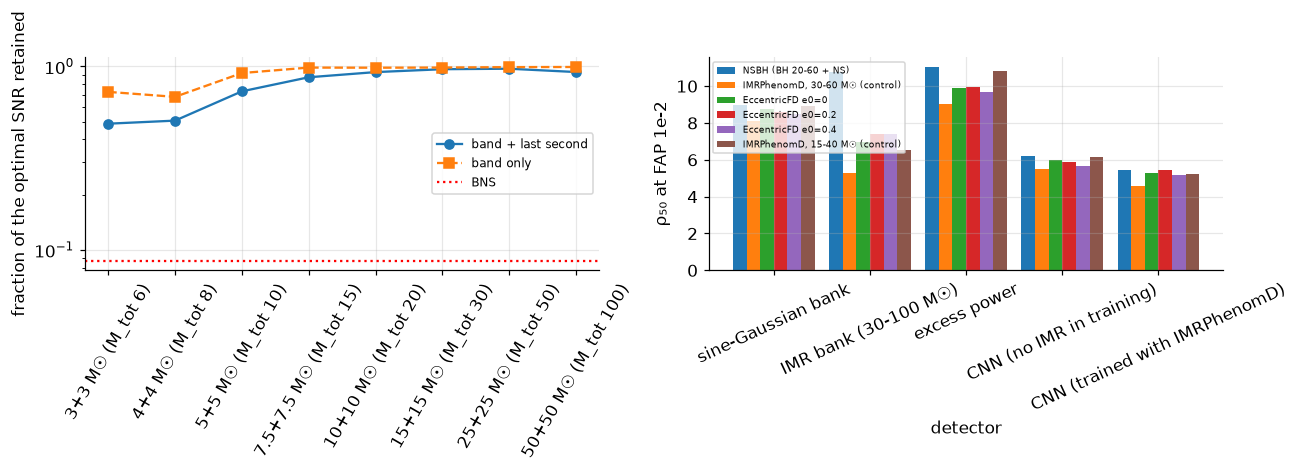

In [5]:
print("FAP 1e-3:"); display(R[R.FAP == 1e-3].pivot_table(index="detector", columns="family", values="rho50", sort=False).round(2))
print("efficiency at rho = 8, FAP 1e-2:"); display(R[R.FAP == 1e-2].pivot_table(index="detector", columns="family", values="eff_rho8", sort=False).round(2))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].semilogy(RET.index[:-1], RET.snr_factor_retained.values[:-1], "o-", label="band + last second"); ax[0].semilogy(RET.index[:-1], np.sqrt(RET.frac_in_band.values[:-1]), "s--", label="band only"); ax[0].axhline(RET.snr_factor_retained.values[-1], color="r", ls=":", label="BNS"); ax[0].set_ylabel("fraction of the optimal SNR retained"); ax[0].tick_params(axis="x", rotation=60); ax[0].legend(fontsize=8)
sub = R[R.FAP == 1e-2].pivot_table(index="detector", columns="family", values="rho50", sort=False); sub.plot.bar(ax=ax[1], width=.85, legend=False); ax[1].set_ylabel("ρ₅₀ at FAP 1e-2"); ax[1].tick_params(axis="x", rotation=25); ax[1].legend(fontsize=6, loc="upper left")
fig.tight_layout(); g.savefig(fig, "fig37_limits"); plt.show()
g.save_json(dict(retention=RET.reset_index().to_dict("records"), rho50=R.to_dict("records")), "37_summary.json")

## Output and next step

`results/37_summary.json`, `figures/fig37_limits`. Next: the final slides.